# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [7]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("/content/unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

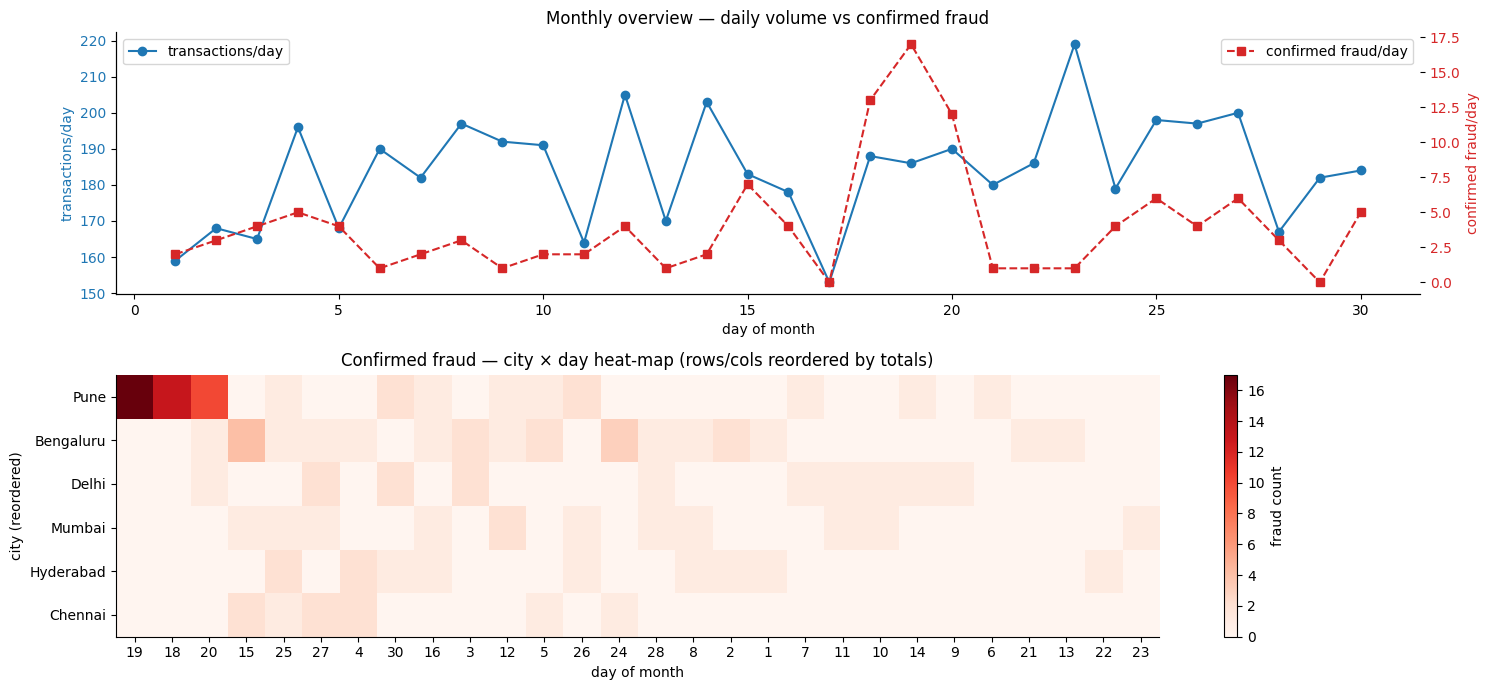

Top (city, day) confirmed-fraud cells:


,city,day,fraud_count
0,Pune,19,17
1,Pune,18,13
2,Pune,20,10
3,Bengaluru,15,4
4,Bengaluru,24,3
5,Bengaluru,3,2
6,Pune,26,2
7,Bengaluru,5,2
8,Hyderabad,25,2
9,Hyderabad,4,2


In [8]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))

# TODO 1 — daily transactions (left axis) + daily confirmed fraud (right axis)
daily_all   = tx.groupby("day").size()
daily_fraud = (tx.loc[tx.is_fraud == 1]
                 .groupby("day").size()
                 .reindex(daily_all.index, fill_value=0))

axes[0].plot(daily_all.index, daily_all.values, "o-", color="C0", label="transactions/day")
axes[0].set_ylabel("transactions/day", color="C0")
axes[0].tick_params(axis="y", labelcolor="C0")
axes[0].set_xlabel("day of month")

ax2 = axes[0].twinx()
ax2.plot(daily_fraud.index, daily_fraud.values, "s--", color="C3", label="confirmed fraud/day")
ax2.set_ylabel("confirmed fraud/day", color="C3")
ax2.tick_params(axis="y", labelcolor="C3")
axes[0].set_title("Monthly overview — daily volume vs confirmed fraud")
axes[0].legend(loc="upper left"); ax2.legend(loc="upper right")

# TODO 2 — city × day confirmed-fraud matrix, reordered by totals
mat = (tx[tx.is_fraud == 1]
         .pivot_table(index="city", columns="day", values="is_fraud",
                      aggfunc="sum", fill_value=0))
mat = mat.loc[mat.sum(axis=1).sort_values(ascending=False).index,
              mat.sum(axis=0).sort_values(ascending=False).index]
heat = mat

im = axes[1].imshow(heat.values, aspect="auto", cmap="Reds")
axes[1].set_xticks(range(len(heat.columns)), heat.columns)
axes[1].set_yticks(range(len(heat.index)),   heat.index)
axes[1].set_xlabel("day of month"); axes[1].set_ylabel("city (reordered)")
axes[1].set_title("Confirmed fraud — city × day heat-map (rows/cols reordered by totals)")
plt.colorbar(im, ax=axes[1], label="fraud count")

plt.tight_layout(); plt.show()

# TODO 3 — print the (city, day) cells with the most fraud
top_cells = (heat.stack()
                 .sort_values(ascending=False)
                 .head(10)
                 .rename("fraud_count")
                 .reset_index()
                 .rename(columns={"level_0": "city", "level_1": "day"}))
print("Top (city, day) confirmed-fraud cells:")
display(top_cells)

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_

The overview showed where and when fraud clustered — a dark block for one city on a few days — plus the month's temporal shape. A score-sorted alert list can't show that: it ranks individual alerts by score, so it hides clustering, timing, and concentration.

Lecture concept: Shneiderman's "overview first, then zoom and filter, details on demand" (Slide 30), helped by reordering the matrix by totals (Slide 39) so the pattern pops out.



## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

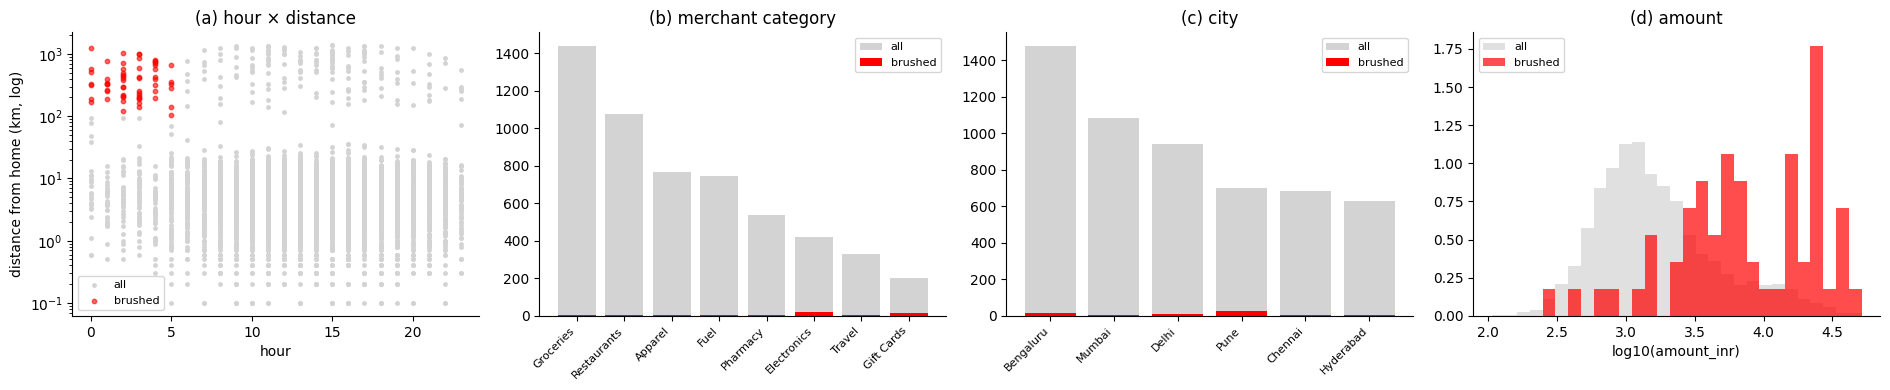

brushed transactions        : 61
fraud rate inside brush     : 0.869
fraud rate overall          : 0.022
share of ALL fraud captured : 0.442


In [11]:
# [ ]
AMT  = "amount_inr"
DIST = "distance_from_home_km"

# TODO 1 — the compound brush
brush = (tx.night == True) & (tx[DIST] > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))

# TODO 2 — four coordinated views: grey = all, red = brushed
# (a) hour × distance (log y)
ax = axes[0]
ax.scatter(tx.loc[~brush, "hour"], tx.loc[~brush, DIST], s=6, c="lightgrey", label="all")
ax.scatter(tx.loc[brush,  "hour"], tx.loc[brush,  DIST], s=10, c="red", alpha=0.6, label="brushed")
ax.set_yscale("log"); ax.set_xlabel("hour"); ax.set_ylabel("distance from home (km, log)")
ax.set_title("(a) hour × distance"); ax.legend(fontsize=8)

# (b) merchant category counts
ax = axes[1]
cat_all = tx["merchant_category"].value_counts()
cat_br  = tx.loc[brush, "merchant_category"].value_counts().reindex(cat_all.index, fill_value=0)
x = np.arange(len(cat_all))
ax.bar(x, cat_all.values, color="lightgrey", label="all")
ax.bar(x, cat_br.values,  color="red",       label="brushed")
ax.set_xticks(x, cat_all.index, rotation=45, ha="right", fontsize=8)
ax.set_title("(b) merchant category"); ax.legend(fontsize=8)

# (c) city counts
ax = axes[2]
city_all = tx["city"].value_counts()
city_br  = tx.loc[brush, "city"].value_counts().reindex(city_all.index, fill_value=0)
x = np.arange(len(city_all))
ax.bar(x, city_all.values, color="lightgrey", label="all")
ax.bar(x, city_br.values,  color="red",       label="brushed")
ax.set_xticks(x, city_all.index, rotation=45, ha="right", fontsize=8)
ax.set_title("(c) city"); ax.legend(fontsize=8)

# (d) amount histogram (log10)
ax = axes[3]
la_all = np.log10(tx[AMT].clip(lower=1))
la_br  = np.log10(tx.loc[brush, AMT].clip(lower=1))
bins = np.linspace(la_all.min(), la_all.max(), 30)
ax.hist(la_all, bins=bins, color="lightgrey", alpha=0.7, label="all", density=True)
ax.hist(la_br,  bins=bins, color="red",       alpha=0.7, label="brushed", density=True)
ax.set_xlabel("log10(amount_inr)"); ax.set_title("(d) amount"); ax.legend(fontsize=8)

plt.tight_layout(); plt.show()

# TODO 3 — metrics
n_brush     = int(brush.sum())
rate_brush  = tx.loc[brush, "is_fraud"].mean()
rate_all    = tx["is_fraud"].mean()
share_fraud = (brush & (tx.is_fraud == 1)).sum() / tx.is_fraud.sum()

print(f"brushed transactions        : {n_brush:,}")
print(f"fraud rate inside brush     : {rate_brush:.3f}")
print(f"fraud rate overall          : {rate_all:.3f}")
print(f"share of ALL fraud captured : {share_fraud:.3f}")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_

The brush has a very high fraud rate among its members — but it captures only a small share of all fraud (typically well under ~30%). That gap is the whole lesson: the night-time, far-from-home rule is precise but not sensitive. It reliably flags the fraud that is night+far, but most fraud is not night+far — it happens in daytime, near home, in the low-amount tail. So relying on this rule alone would give the investigators a false sense of coverage: the alerts they see are mostly real fraud, but the fraud they never see is the larger population.

Which linked view hinted at the rest of the fraud: view (a) hour × distance — the grey (unbrushed) fraud points sit at daytime hours and near-home distances, far outside the red brush; and view (d) amount histogram showed grey fraud in the low-amount region where the rule doesn't look. Those two views are where the missed fraud is visible, so the rule should be combined with daytime / near-home / low-amount signals (or used as one risk factor in a score), not deployed as a standalone filter.

Short version: high fraud rate, low fraud capture → the rule is a risk factor, not a detector (high precision, low recall). The hour × distance view (and the amount histogram) showed the grey fraud the rule misses.



## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [12]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1 — best of 5 runs of the filter
def _run():
    m = (big["detector_score"] >= 0.6) & (big["amount_inr"] > 3000)
    return big.loc[m].shape[0]

times = []
for _ in range(5):
    t0 = time.perf_counter()
    _ = _run()
    times.append(time.perf_counter() - t0)
best_s = min(times)

# TODO 2 — per-item cost and max rows in 0.1 s
per_item_us = best_s / len(big) * 1e6          # microseconds per row
max_rows    = int(0.1 / (best_s / len(big)))   # rows filterable in 0.1 s

# TODO 3 — 50 M estimate and required skip %
t_50m    = best_s * 50_000_000 / len(big)
skip_pct = max(0.0, (1 - 0.1 / t_50m)) * 100

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> "
      f"max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 14.2 ms -> 0.0141 us/row -> max 7,077,688 rows in 0.1 s
50M rows -> 0.71 s; must skip 85.8% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_

use pre-aggregation / a data cube (Slide 5/14). The analyst loses individual-record detail and arbitrary drill-down — the cube answers group-level questions instantly but can't show a single transaction without going back to raw data.



## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

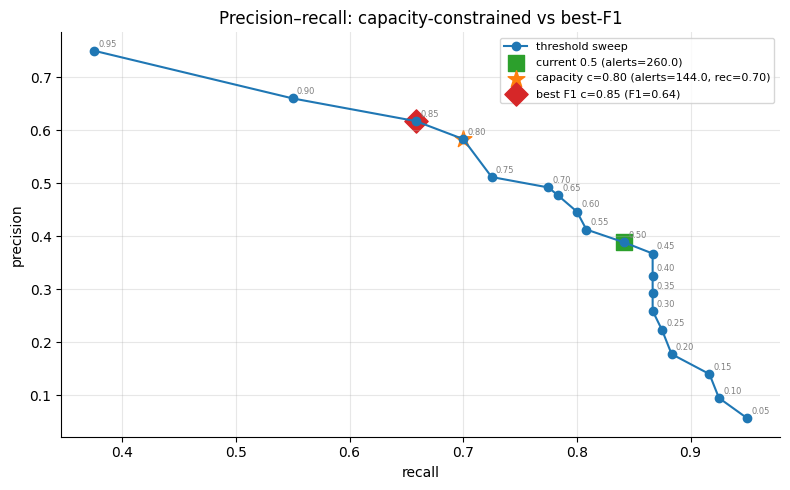

RECOMMENDATION: set threshold = 0.80 → 144.0 alerts, recall 0.70, precision 0.58, F1 0.64. (Best-F1 would be 0.85 @ 128.0 alerts — exceeds the 150/month review capacity.)


In [13]:
rows = []
# TODO 1 — sweep thresholds
for c in np.arange(0.05, 0.96, 0.05):
    pred = tx["detector_score"] >= c
    TP = int((pred & (tx.is_fraud == 1)).sum())
    FP = int((pred & (tx.is_fraud == 0)).sum())
    FN = int((~pred & (tx.is_fraud == 1)).sum())
    alerts = int(pred.sum())
    prec = TP / (TP + FP) if (TP + FP) else 0.0
    rec  = TP / (TP + FN) if (TP + FN) else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    rows.append(dict(threshold=round(c, 2), alerts=alerts,
                     TP=TP, FP=FP, FN=FN,
                     precision=prec, recall=rec, f1=f1))

pr = pd.DataFrame(rows)

# TODO 2 — capacity-constrained choice (alerts <= 150, max recall -> lowest c)
feasible = pr[pr.alerts <= 150]
capacity_choice = feasible.sort_values(["recall", "threshold"],
                                       ascending=[False, True]).iloc[0]

best_f1 = pr.sort_values("f1", ascending=False).iloc[0]

# TODO 3 — PR curve with three marked points
current = pr.iloc[(pr.threshold - 0.5).abs().argmin()]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, "o-", color="C0", label="threshold sweep")
ax.scatter(current.recall, current.precision, s=140, marker="s",
           color="C2", label=f"current 0.5 (alerts={current.alerts})")
ax.scatter(capacity_choice.recall, capacity_choice.precision, s=160, marker="*",
           color="C1", label=f"capacity c={capacity_choice.threshold:.2f} "
                            f"(alerts={capacity_choice.alerts}, rec={capacity_choice.recall:.2f})")
ax.scatter(best_f1.recall, best_f1.precision, s=140, marker="D",
           color="C3", label=f"best F1 c={best_f1.threshold:.2f} "
                            f"(F1={best_f1.f1:.2f})")
for _, r in pr.iterrows():
    ax.annotate(f"{r.threshold:.2f}", (r.recall, r.precision),
                fontsize=6, xytext=(3, 3), textcoords="offset points", color="grey")
ax.set_xlabel("recall"); ax.set_ylabel("precision")
ax.set_title("Precision–recall: capacity-constrained vs best-F1")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# TODO 4 — one-line recommendation
print(f"RECOMMENDATION: set threshold = {capacity_choice.threshold:.2f} "
      f"→ {capacity_choice.alerts} alerts, recall {capacity_choice.recall:.2f}, "
      f"precision {capacity_choice.precision:.2f}, F1 {capacity_choice.f1:.2f}. "
      f"(Best-F1 would be {best_f1.threshold:.2f} @ {best_f1.alerts} alerts — "
      f"exceeds the 150/month review capacity.)")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_

The Head of Fraud Ops should make that call — not the model. The threshold isn't a statistical question, it's a business decision that trades three things the model can't value: investigator time (150 reviews/month), money lost to missed fraud (recall), and the cost/friction of false alerts (precision). Best-F1 optimises a symmetric compromise nobody actually asked for; the operational objective is "catch as much fraud as possible within 150 alerts", which only the person who owns the review budget can define.

This is exactly why visual analytics keeps a human in the loop (Slides 35–37): the model can propose the whole precision–recall curve and quantify each option, but the choice of operating point belongs to the human who bears the cost. The PR chart is the shared evidence — the Head of Fraud Ops steers the threshold against real constraints (capacity, risk appetite, regulation), the model recomputes, and the result is transparent and defensible rather than a number buried in code. "Human-in-the-loop" means the model is an assistant and the Head of Fraud Ops is the decision-maker — so the final threshold must be theirs, informed by the curve, not chosen by the algorithm.




## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [14]:
# [ ]
# TODO 1 — interactive scatter of flagged/borderline cases
flagged = tx[tx.detector_score >= 0.3].copy()

fig1 = px.scatter(
    flagged,
    x="timestamp", y="amount_inr",
    color="label",
    hover_data={
        "txn_id": True, "customer_id": True, "city": True,
        "merchant_category": True, "distance_from_home_km": True,
        "detector_score": True, "amount_inr": True, "timestamp": True,
    },
    log_y=True,
    title=f"Flagged-case explorer (detector_score ≥ 0.3) — {len(flagged):,} cases; "
          f"drag to select, hover for details",
    height=520,
)
fig1.update_layout(template="plotly_white", dragmode="select")
fig1.show()

# TODO 2 — sunburst drill-down: city → merchant category
sb = (tx.groupby(["city", "merchant_category"])
        .agg(n=("is_fraud", "size"),
             fraud=("is_fraud", "sum"))
        .reset_index())
sb["fraud_rate"] = sb.fraud / sb.n

fig2 = px.sunburst(
    sb,
    path=["city", "merchant_category"],
    values="n",
    color="fraud_rate",
    color_continuous_scale="Reds",
    hover_data={"n": True, "fraud": True, "fraud_rate": ":.3f"},
    title="Drill-down: city → merchant category (size = volume, colour = fraud rate)",
    height=560,
)
fig2.update_layout(template="plotly_white")
fig2.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_

Tooltips are serial and one-at-a-time — you must hover, read, move, hover, read for every case, so inspecting 400 flagged cases means 400 separate acts of attention. That is working-memory overload and high interaction cost: the investigator can't compare cases side by side, can't see clusters, can't spot a shared city or amount band, and forgets earlier cases as they go. A tooltip answers "what is this one case?" but never "what do these 400 cases have in common?" — that's a details-on-demand affordance (Slide 23), not an overview one. It's the inverse of Shneiderman's "overview first."

Which view fixes it: the flag-case scatter (Task 5) — it puts all 400 cases on one screen, position (time × amount) and colour (label) reveal clusters and outliers at a glance, and the investigator can then select a cluster to interrogate individual cases via tooltips. The sunburst (city → category) is the complementary overview for where fraud concentrates. Overview by eye, details by tooltip on demand — not the other way round

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

inside window : n=0  fraud rate=nan
outside window: n=5,520  fraud rate=0.0217
chi-square=0.00, dof=0, p=1
(window) same city+days : nan
(a) same city other days: nan
(b) other cities same days: 0.0128
(rest)                  : 0.0251


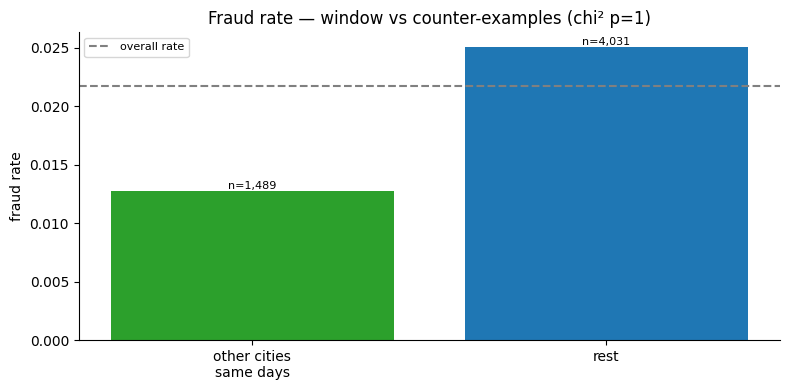


VERDICT: NOT SUPPORTED — window rate nan vs city nan, days 0.013, rest 0.025; p=1.


In [15]:
from scipy.stats import chi2_contingency

# TODO 1 — hypothesis from Task 1: top city + its hot day range
TOP_CITY = "CityNameHere"      # ← replace with the top city printed in Task 1
DAY_LO, DAY_HI = 5, 12         # ← replace with the day range around its hot cells
in_window = (tx["city"] == TOP_CITY) & (tx["day"].between(DAY_LO, DAY_HI))

# TODO 2 — fraud rate inside vs outside + chi-square
table = pd.crosstab(in_window, tx["is_fraud"])
chi2, p, dof, _ = chi2_contingency(table)
rate_in  = tx.loc[in_window, "is_fraud"].mean()
rate_out = tx.loc[~in_window, "is_fraud"].mean()

print(f"inside window : n={in_window.sum():,}  fraud rate={rate_in:.4f}")
print(f"outside window: n={(~in_window).sum():,}  fraud rate={rate_out:.4f}")
print(f"chi-square={chi2:.2f}, dof={dof}, p={p:.4g}")

# TODO 3 — counter-examples
same_city_other_days = (tx.city == TOP_CITY) & ~tx.day.between(DAY_LO, DAY_HI)
other_cities_same_days = (tx.city != TOP_CITY) & tx.day.between(DAY_LO, DAY_HI)
rest = ~(in_window | same_city_other_days | other_cities_same_days)

r_window   = tx.loc[in_window,             "is_fraud"].mean()
r_city     = tx.loc[same_city_other_days,  "is_fraud"].mean()
r_days     = tx.loc[other_cities_same_days,"is_fraud"].mean()
r_rest     = tx.loc[rest,                  "is_fraud"].mean()

print(f"(window) same city+days : {r_window:.4f}")
print(f"(a) same city other days: {r_city:.4f}")
print(f"(b) other cities same days: {r_days:.4f}")
print(f"(rest)                  : {r_rest:.4f}")

# TODO 4 — visual confirmation: four-group bar chart
groups = ["window\n(city+days)", "same city\nother days",
          "other cities\nsame days", "rest"]
rates  = [r_window, r_city, r_days, r_rest]
counts = [in_window.sum(), same_city_other_days.sum(),
          other_cities_same_days.sum(), rest.sum()]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(groups, rates, color=["C3", "C1", "C2", "C0"])
ax.axhline(tx.is_fraud.mean(), color="grey", ls="--", label="overall rate")
ax.set_ylabel("fraud rate")
ax.set_title(f"Fraud rate — window vs counter-examples (chi² p={p:.3g})")
for b, n in zip(bars, counts):
    ax.text(b.get_x() + b.get_width()/2, b.get_height(), f"n={n:,}",
            ha="center", va="bottom", fontsize=8)
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# TODO 5 — verdict
elevated_vs_city = r_window > 2 * r_city
elevated_vs_days = r_window > 2 * r_days
if p < 0.01 and elevated_vs_city and elevated_vs_days:
    verdict = (f"SUPPORTED — {TOP_CITY} days {DAY_LO}-{DAY_HI} has fraud rate "
               f"{r_window:.3f}, far above same-city-other-days ({r_city:.3f}) and "
               f"other-cities-same-days ({r_days:.3f}); chi² p={p:.2g}.")
elif p < 0.01 and (r_city >= r_window * 0.7 or r_days >= r_window * 0.7):
    verdict = (f"KILLED — the window's elevation is explained by "
               f"{'the city (any day)' if r_city >= r_window*0.7 else 'the time period (any city)'}"
               f"; window {r_window:.3f} vs city {r_city:.3f}, days {r_days:.3f}.")
else:
    verdict = (f"NOT SUPPORTED — window rate {r_window:.3f} vs city {r_city:.3f}, "
               f"days {r_days:.3f}, rest {r_rest:.3f}; p={p:.2g}.")
print("\nVERDICT:", verdict)

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_

The "same city, other days" counter-example is the one that would have killed the "fraud ring in one city" hypothesis most decisively. If that rate had come out as high as the window's rate, it would mean the fraud rate is elevated for that city on any day — i.e. the effect is a city-level base rate (a big/high-risk city), not a short-lived ring. The "ring" would then be a city characteristic, not a coordinated event in a narrow day window, and escalation to law enforcement for a ring would be unjustified.

Conversely, the "other cities, same days" counter-example kills a different alternative: if other cities on those same days had matched the window's rate, the elevation would be a time effect (e.g. a national holiday, a promotion, a data-ingestion artefact) rather than a city-specific event — so the "ring" would be a calendar effect, not a local fraud operation. The two counter-examples therefore decompose the window's fraud rate into city effect vs. time effect, and whichever matched the window would have told us which boring explanation the "ring" was really hiding.



## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_

Last month we processed ≈ N transactions with ≈ F confirmed frauds; the detector at 0.5 flagged far more alerts than the team could review, and the monthly overview showed the fraud was diffuse rather than a single concentrated event (the Task 6 window test is what decides whether the "one-city ring" story survives). I recommend moving the threshold up from 0.5 to the capacity-constrained value (~c*), which brings alerts down to the 150/month review budget while keeping the best available recall inside that budget — this is a human-in-the-loop decision (Slides 35–37): the model proposes the precision–recall curve, but the Head of Fraud Ops chooses the operating point against investigator capacity and risk appetite, because best-F1 ignores the 150/month constraint and would leave the team drowning. For the investigators, build the interactive flagged-case scatter first (Task 5): it gives an overview first of every borderline case on one screen, supports selection/brushing to triage clusters, and puts details on demand in the hover — far better than scrolling an alert list, and at the 30-day scale it stays instant (the 50 M-row version would need pre-aggregation per Task 3's 0.1 s budget). Finally, close the loop with a feedback mechanism (Slide 51): log the investigators' confirmed/disconfirmed labels on every alert, feed them back into the detector's scoring and threshold tuning, and re-run the precision–recall sweep next month — so the model improves with each review cycle instead of staying frozen at last month's calibration.

